# 02 — Exploração e Limpeza dos Dados (EDA)

Este notebook realiza o carregamento, entendimento estrutural, limpeza, padronização e análise exploratória dos metadados do dataset **NIH Chest X-ray (`Data_Entry_2017_v2020.csv`)**.

## 1. Configurações e Importações

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# Garante que a raiz do projeto está no sys.path para importar src/
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

print(f"Raiz do projeto: {ROOT}")

Raiz do projeto: /home/carolina/Documents/Triagem_de_Raio-X


In [3]:
# ── Diretórios ───────────────────────────────────────────────────────
PASTA_RAW_DATA = Path(ROOT, "data", "raw")
PASTA_RAW_DATA.mkdir(parents=True, exist_ok=True)

PASTA_INPUT_DATA = Path(ROOT, "data", "input")
PASTA_INPUT_DATA.mkdir(parents=True, exist_ok=True)

## 2. Carregamento e Visão Geral do Dataset

In [4]:
data = os.listdir(PASTA_RAW_DATA)
path_df = [i for i in data if i.endswith(".csv")]
df = pd.read_csv(PASTA_RAW_DATA / path_df[0])
df.head(10)

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168
5,00000003_002.png,Hernia,1,3,75,F,PA,2048,2500,0.168,0.168
6,00000003_003.png,Hernia|Infiltration,2,3,76,F,PA,2698,2991,0.143,0.143
7,00000003_004.png,Hernia,3,3,77,F,PA,2500,2048,0.168,0.168
8,00000003_005.png,Hernia,4,3,78,F,PA,2686,2991,0.143,0.143
9,00000003_006.png,Hernia,5,3,79,F,PA,2992,2991,0.143,0.143


### 2.1. Dicionário de Colunas

In [5]:
dados_dicionario = {
    "Coluna": [
        "Image Index", "Finding Labels", "Follow-up #", "Patient ID",
        "Patient Age", "Patient Sex", "View Position", "OriginalImage[Width",
        "Height]", "OriginalImagePixelSpacing[x", "y]"
    ],
    "Significado_no_Dataset": [
        "Nome exato do arquivo da imagem (ex: 00000001_000.png).",
        "Doenças encontradas separadas por '|' ou 'No Finding'.",
        "Número do exame na linha do tempo do paciente (acumulativo a partir de 0).",
        "Código único que identifica o paciente.",
        "Idade do paciente no momento do raio-X.",
        "Sexo biológico do paciente (M/F).",
        "Posição do disparo do raio-X (PA ou AP).",
        "Largura da imagem original em pixels.",
        "Altura da imagem original em pixels.",
        "Distância física entre pixels no eixo X (mm).",
        "Distância física entre pixels no eixo Y (mm)."
    ],
    "Relevancia_para_o_Projeto": [
        "Chave primária para carregar a imagem.",
        "Target (Y) que o modelo vai prever.",
        "Útil para analisar evolução temporal e frequência de acompanhamento.",
        "Evita data leakage na separação treino/validação/teste.",
        "Feature demográfica adicional.",
        "Feature demográfica (análise de prevalência e viés).",
        "Diferencia exames ambulatoriais/rotina (PA) de leito/UTI (AP).",
        "Informativo para pré-processamento e redimensionamento.",
        "Informativo para pré-processamento e redimensionamento.",
        "Cálculos de escala física/anatômica real.",
        "Cálculos de escala física/anatômica real."
    ]
}

df_dicionario = pd.DataFrame(dados_dicionario)
df_dicionario

,Coluna,Significado_no_Dataset,Relevancia_para_o_Projeto
0,Image Index,Nome exato do arquivo da imagem (ex: 00000001_...,Chave primária para carregar a imagem.
1,Finding Labels,Doenças encontradas separadas por '|' ou 'No F...,Target (Y) que o modelo vai prever.
2,Follow-up #,Número do exame na linha do tempo do paciente ...,Útil para analisar evolução temporal e frequên...
3,Patient ID,Código único que identifica o paciente.,Evita data leakage na separação treino/validaç...
4,Patient Age,Idade do paciente no momento do raio-X.,Feature demográfica adicional.
5,Patient Sex,Sexo biológico do paciente (M/F).,Feature demográfica (análise de prevalência e ...
6,View Position,Posição do disparo do raio-X (PA ou AP).,Diferencia exames ambulatoriais/rotina (PA) de...
7,OriginalImage[Width,Largura da imagem original em pixels.,Informativo para pré-processamento e redimensi...
8,Height],Altura da imagem original em pixels.,Informativo para pré-processamento e redimensi...
9,OriginalImagePixelSpacing[x,Distância física entre pixels no eixo X (mm).,Cálculos de escala física/anatômica real.


### 2.2. Estrutura e Estatísticas Descritivas

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 11 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  object 
 1   Finding Labels               112120 non-null  object 
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Sex                  112120 non-null  object 
 6   View Position                112120 non-null  object 
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
dtypes: float64(2), int64(5), object(4)
memory usage: 9.4+ MB


In [7]:
df.describe()

,Follow-up #,Patient ID,Patient Age,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
count,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000
mean,8.573751,14346.381743,46.626365,2646.078844,2486.438842,0.155649,0.155649
std,15.406320,8403.876972,16.602680,341.246429,401.268227,0.016174,0.016174
min,0.000000,1.000000,0.000000,1143.000000,966.000000,0.115000,0.115000
25%,0.000000,7310.750000,34.000000,2500.000000,2048.000000,0.143000,0.143000
50%,3.000000,13993.000000,49.000000,2518.000000,2544.000000,0.143000,0.143000
75%,10.000000,20673.000000,59.000000,2992.000000,2991.000000,0.168000,0.168000
max,183.000000,30805.000000,95.000000,3827.000000,4715.000000,0.198800,0.198800


### 2.3. Entendendo a Posição do Exame (`View Position`: PA vs. AP)

| Característica | PA (Posteroanterior) | AP (Anteroposterior) |
| :--- | :--- | :--- |
| **Cenário clínico** | Exames de **rotina** e ambulatório. | Pacientes de **UTI**, emergência ou acamados. |
| **Direção do raio-X** | Entra pelas costas (posterior) e sai pela frente (anterior). | Entra pela frente (anterior) e sai pelas costas (posterior). |
| **Posição do paciente** | Em pé, com o peito encostado no detector. | Deitado ou sentado no leito (aparelho portátil). |
| **Qualidade e anatomia** | Melhor definição pulmonar e tamanho real do coração. | Coração parece maior (magnificação) e escápulas podem sobrepor os pulmões. |
| **Perfil no dataset** | Maior proporção de exames normais (`No Finding`) e acompanhamento. | Maior concentração de achados críticos (ex: derrame pleural, edema). |

## 3. Limpeza e Transformação dos Dados

### 3.1. Verificação da Variável Idade e Valores Nulos

In [8]:
print("Idade máxima:", df["Patient Age"].max())
print("Idade mínima:", df["Patient Age"].min())
print("Total de nulos:", df["Patient Age"].isna().sum())

Idade máxima: 95
Idade mínima: 0
Total de nulos: 0


> **Conclusão:** Na versão `v2020` do dataset, não há valores nulos nem idades inválidas (o intervalo vai de `0` a `95` anos), portanto não é necessário remover registros por inconsistência de idade.

### 3.2. Padronização dos Nomes das Colunas

As colunas originais possuem espaços e colchetes partidos (como `OriginalImage[Width`, `Height]`, `Follow-up #`). Abaixo criamos um mapeamento padronizado em `snake_case` caso queiramos consultar com nomes limpos:

In [9]:
MAPA_COLUNAS = {
    "Image Index": "image_index",
    "Finding Labels": "finding_labels",
    "Follow-up #": "follow_up_num",
    "Patient ID": "patient_id",
    "Patient Age": "patient_age",
    "Patient Sex": "patient_sex",
    "View Position": "view_position",
    "OriginalImage[Width": "img_width",
    "Height]": "img_height",
    "OriginalImagePixelSpacing[x": "pixel_spacing_x",
    "y]": "pixel_spacing_y",
}

df_padronizado = df.rename(columns=MAPA_COLUNAS)
print("Colunas padronizadas:", list(df_padronizado.columns))

Colunas padronizadas: ['image_index', 'finding_labels', 'follow_up_num', 'patient_id', 'patient_age', 'patient_sex', 'view_position', 'img_width', 'img_height', 'pixel_spacing_x', 'pixel_spacing_y']


### 3.3. Separação dos Achados Clínicos (`Finding Labels`)

Como um mesmo exame pode apresentar múltiplas patologias separadas por `|`, separamos os achados em colunas individuais (`achado 1` até `achado 9`) e calculamos a coluna `numero de achados` (atribuindo `0` quando o rótulo é `No Finding`).

In [10]:
# 1. Separa a coluna 'Finding Labels' pelo '|' criando novas colunas automaticamente
achados_split = df["Finding Labels"].str.split("|", expand=True)

# 2. Renomeia as colunas geradas para 'achado 1', 'achado 2', 'achado 3', etc.
achados_split.columns = [f"achado {i + 1}" for i in range(achados_split.shape[1])]

# 3. Junta as novas colunas ao DataFrame original
df2 = pd.concat([df, achados_split], axis=1)

# 4. Cria a coluna 'numero de achados' (considerando 'No Finding' como 0)
df2["numero de achados"] = np.where(
    df["Finding Labels"] == "No Finding",
    0,
    df["Finding Labels"].str.count(r"\|") + 1
)

# Visualiza o resultado
colunas_exibir = ["Finding Labels", "numero de achados"] + list(achados_split.columns)
df2[colunas_exibir]

,Finding Labels,numero de achados,achado 1,achado 2,achado 3,achado 4,achado 5,achado 6,achado 7,achado 8,achado 9
0,Cardiomegaly,1,Cardiomegaly,None,None,None,None,None,None,None,None
1,Cardiomegaly|Emphysema,2,Cardiomegaly,Emphysema,None,None,None,None,None,None,None
2,Cardiomegaly|Effusion,2,Cardiomegaly,Effusion,None,None,None,None,None,None,None
3,No Finding,0,No Finding,None,None,None,None,None,None,None,None
4,Hernia,1,Hernia,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...
112115,Mass|Pneumonia,2,Mass,Pneumonia,None,None,None,None,None,None,None
112116,No Finding,0,No Finding,None,None,None,None,None,None,None,None
112117,No Finding,0,No Finding,None,None,None,None,None,None,None,None
112118,No Finding,0,No Finding,None,None,None,None,None,None,None,None


Verificando os exames com maior quantidade simultânea de patologias (`numero de achados > 8`):

In [11]:
df2[df2["numero de achados"] > 8]

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,...,achado 1,achado 2,achado 3,achado 4,achado 5,achado 6,achado 7,achado 8,achado 9,numero de achados
83884,00020622_003.png,Atelectasis|Consolidation|Effusion|Fibrosis|In...,3,20622,74,F,PA,2496,3024,0.139,...,Atelectasis,Consolidation,Effusion,Fibrosis,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumothorax,9
96044,00025262_000.png,Atelectasis|Consolidation|Edema|Effusion|Infil...,0,25262,45,M,AP,3056,2544,0.139,...,Atelectasis,Consolidation,Edema,Effusion,Infiltration,Mass,Nodule,Pleural_Thickening,Pneumonia,9


## 4. Análise Exploratória de Dados (EDA)

### 4.1. Perfil Demográfico e Posição do Exame

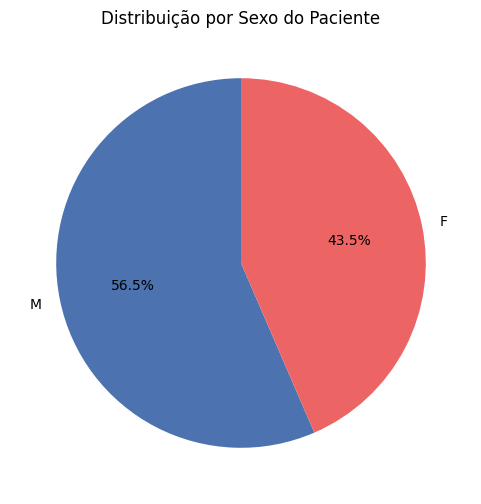

In [12]:
contagem = df["Patient Sex"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    contagem.values,
    labels=contagem.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C72B0", "#ED6464"]
)

plt.title("Distribuição por Sexo do Paciente")
plt.show()

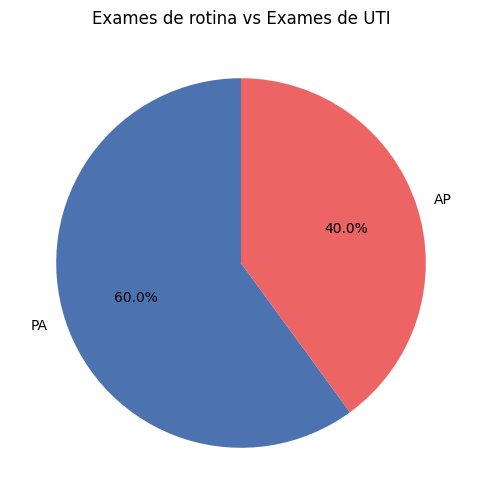

In [13]:
contagem = df["View Position"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    contagem.values,
    labels=contagem.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C72B0", "#ED6464"]
)

plt.title("Exames de Rotina (PA) vs Exames de UTI (AP)")
plt.show()

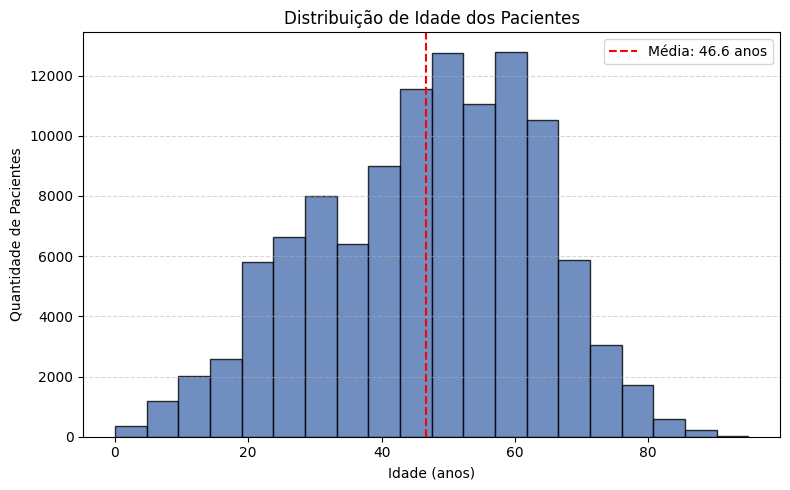

In [14]:
idades = df["Patient Age"].dropna()
idades = idades[idades <= 110]

# 2. Cria o histograma
plt.figure(figsize=(8, 5))
plt.hist(idades, bins=20, color="#4C72B0", edgecolor="black", alpha=0.8)

# 3. Adiciona linha vertical com a média de idade (opcional, mas útil)
media = idades.mean()
plt.axvline(media, color="red", linestyle="dashed", linewidth=1.5, label=f"Média: {media:.1f} anos")

# 4. Ajustes visuais
plt.title("Distribuição de Idade dos Pacientes")
plt.xlabel("Idade (anos)")
plt.ylabel("Quantidade de Pacientes")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 4.2. Quantidade de Doenças e Prevalência por Sexo do Paciente

Abaixo investigamos se há diferença na quantidade de achados por exame e na prevalência de cada patologia entre pacientes do sexo masculino (`M`) e feminino (`F`).

In [15]:
# Resumo de quantidade de achados por sexo
resumo_sexo = df2.groupby("Patient Sex").agg(
    total_exames=("Image Index", "count"),
    media_achados=("numero de achados", "mean"),
    exames_com_doenca=("numero de achados", lambda s: (s > 0).sum()),
)
resumo_sexo["%_com_doenca"] = (resumo_sexo["exames_com_doenca"] / resumo_sexo["total_exames"] * 100).round(1)
resumo_sexo

             total_exames  media_achados  exames_com_doenca  %_com_doenca
Patient Sex                                                              
F                   48780       0.708262              22341          45.8
M                   63340       0.731102              29418          46.4

In [16]:
# Explosão dos achados para contar cada patologia individualmente por sexo
df_explodido = df[["Patient Sex", "Finding Labels"]].assign(
    patologia=df["Finding Labels"].str.split("|")
).explode("patologia")

tabela_patologias = pd.crosstab(df_explodido["patologia"], df_explodido["Patient Sex"])
tabela_patologias["Total"] = tabela_patologias["M"] + tabela_patologias["F"]
tabela_patologias["%_M"] = (tabela_patologias["M"] / tabela_patologias["Total"] * 100).round(1)
tabela_patologias["%_F"] = (tabela_patologias["F"] / tabela_patologias["Total"] * 100).round(1)
tabela_patologias = tabela_patologias.sort_values("Total", ascending=False)
tabela_patologias

Patient Sex             F      M  Total   %_M   %_F
patologia                                          
No Finding          26439  33922  60361  56.2  43.8
Infiltration         8467  11427  19894  57.4  42.6
Effusion             5882   7435  13317  55.8  44.2
Atelectasis          4653   6906  11559  59.7  40.3
Nodule               2646   3685   6331  58.2  41.8
Mass                 2253   3529   5782  61.0  39.0
Pneumothorax         2585   2717   5302  51.2  48.8
Consolidation        2001   2666   4667  57.1  42.9
Pleural_Thickening   1343   2042   3385  60.3  39.7
Cardiomegaly         1469   1307   2776  47.1  52.9
Emphysema             906   1610   2516  64.0  36.0
Edema                1099   1204   2303  52.3  47.7
Fibrosis              771    915   1686  54.3  45.7
Pneumonia             593    838   1431  58.6  41.4
Hernia                131     96    227  42.3  57.7

**Principais observações por sexo:**
- A proporção global de exames com alguma patologia é muito próxima entre homens (**46,4%**) e mulheres (**45,8%**), com média de ~0,72 achado por exame.
- Embora os homens representem **56,5%** da base total, algumas doenças têm concentração ainda mais acentuada no sexo masculino, como **Emphysema (64,0% M)**, **Mass (61,0% M)** e **Pleural Thickening (60,3% M)**.
- Em contrapartida, o sexo feminino apresenta maioria absoluta nos casos de **Hernia (57,7% F)** e **Cardiomegaly (52,9% F)**.

### 4.3. Como Múltiplos Exames do Mesmo Paciente (`Follow-up #`) Influenciam a Base?

In [17]:
total_exames = len(df)
total_pacientes = df["Patient ID"].nunique()
exames_por_paciente = df.groupby("Patient ID")["Image Index"].count()

pacientes_unico_exame = (exames_por_paciente == 1).sum()
pacientes_multi_exames = (exames_por_paciente > 1).sum()
exames_de_recorrentes = exames_por_paciente[exames_por_paciente > 1].sum()

print(f"Total de exames no dataset: {total_exames:,}")
print(f"Total de pacientes únicos:  {total_pacientes:,}")
print(f"Pacientes com apenas 1 exame: {pacientes_unico_exame:,} ({pacientes_unico_exame / total_pacientes * 100:.1f}% dos pacientes)")
print(f"Pacientes com múltiplos exames: {pacientes_multi_exames:,} ({pacientes_multi_exames / total_pacientes * 100:.1f}% dos pacientes)")
print(f"Exames gerados por pacientes recorrentes: {exames_de_recorrentes:,} ({exames_de_recorrentes / total_exames * 100:.1f}% de toda a base!)")
print("\nTop 5 pacientes com mais exames realizados:")
print(exames_por_paciente.sort_values(ascending=False).head(5))

Total de exames no dataset: 112,120
Total de pacientes únicos:  30,805
Pacientes com apenas 1 exame: 17,503 (56.8% dos pacientes)
Pacientes com múltiplos exames: 13,302 (43.2% dos pacientes)
Exames gerados por pacientes recorrentes: 94,617 (84.4% de toda a base!)

Top 5 pacientes com mais exames realizados:
Patient ID
10007    184
13670    173
15530    158
12834    157
13993    143
Name: Image Index, dtype: int64


#### Impactos diretos no projeto e na modelagem:
1. **Risco crítico de *Data Leakage* (Vazamento de Dados):**
   - Como **84,4% dos exames** pertencem a pacientes que fizeram mais de um raio-X (chegando a 184 exames de um único paciente), uma divisão aleatória simples (`train_test_split`) colocaria exames do mesmo paciente tanto no treino quanto no teste.
   - Isso faria a rede neural memorizar a anatomia específica, marca-passos ou artefatos daquele indivíduo, inflando artificialmente as métricas de avaliação.
   - **Solução obrigatória:** Utilizar divisão agrupada por `Patient ID` (ex: `GroupShuffleSplit` ou `GroupKFold`), garantindo que todos os exames de um paciente fiquem exclusivamente em uma única partição.
2. **Viés de Gravidade e Representatividade (*Selection/Severity Bias*):**
   - Pacientes com `Follow-up #` alto geralmente estão internados em UTI (`View Position = AP`) ou em acompanhamento crônico prolongado, apresentando maior concentração de achados complexos e dispositivos médicos (tubos, cateteres).
3. **Dependência Estatística:**
   - As 112.120 imagens não são amostras 100% independentes entre si; na prática, temos 30.805 trajetórias clínicas distintas.